# Q-Kernel Force — Quantum Kernel Classifier

## 1. Objective
Compare a quantum-kernel SVM against classical SVM baselines.
Results must be measured; quantum advantage is not assumed.


In [1]:
import sys
print(sys.executable)

/home/chinnu/qff-2026-q-kernel-force/.venv/bin/python


## 2. Imports and environment

In [2]:
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import qiskit
import qiskit_aer
import sklearn

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score

from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityQuantumKernel

SEED = 42
ROOT = Path.cwd().resolve().parent
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version())
print("Qiskit:", qiskit.__version__)
print("Aer:", qiskit_aer.__version__)
print("scikit-learn:", sklearn.__version__)
print("Project root:", ROOT)


Python: 3.12.3
Qiskit: 2.6.0
Aer: 0.17.2
scikit-learn: 1.9.1
Project root: /home/chinnu/qff-2026-q-kernel-force/rebuild


## 3. Dataset and preprocessing
Split the data before fitting PCA or scaling to avoid test-data leakage.


In [3]:
digits = load_digits()
mask = np.isin(digits.target, [0, 1])
X = digits.data[mask]
y = digits.target[mask]

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

preprocessor = Pipeline([
    ("pca", PCA(n_components=4)),
    ("scale", MinMaxScaler(feature_range=(0, np.pi / 2)))
])
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("Training samples:", len(y_train))
print("Test samples:", len(y_test))
print("Features:", X_train.shape[1])


Training samples: 270
Test samples: 90
Features: 4


## 4. Classical baselines

In [4]:
models = {
    "Classical RBF SVM": SVC(kernel="rbf"),
    "Classical polynomial SVM": SVC(kernel="poly")
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred)
    })

classical_results = pd.DataFrame(rows)
classical_results


,model,accuracy,balanced_accuracy
0,Classical RBF SVM,1.000000,1.000000
1,Classical polynomial SVM,0.955556,0.955556


## 5. Ideal quantum-kernel SVM
This is an ideal kernel simulation, not a noisy hardware result.


In [5]:
feature_map = zz_feature_map(
    feature_dimension=X_train.shape[1],
    reps=2,
    entanglement="linear"
)

kernel = FidelityQuantumKernel(feature_map=feature_map)

print("Computing training kernel...")
K_train = kernel.evaluate(x_vec=X_train)

print("Computing test kernel...")
K_test = kernel.evaluate(x_vec=X_test, y_vec=X_train)

quantum_model = SVC(kernel="precomputed")
quantum_model.fit(K_train, y_train)
quantum_pred = quantum_model.predict(K_test)

quantum_results = pd.DataFrame([{
    "model": "Ideal quantum-kernel SVM",
    "accuracy": accuracy_score(y_test, quantum_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, quantum_pred)
}])
quantum_results


Computing training kernel...


Computing test kernel...


,model,accuracy,balanced_accuracy
0,Ideal quantum-kernel SVM,0.944444,0.944444


## 6. Save initial comparison
Single-split results are preliminary and do not establish quantum advantage.


In [6]:
comparison = pd.concat(
    [classical_results, quantum_results],
    ignore_index=True
)
comparison["dataset"] = "Digits 0 vs 1"
comparison["seed"] = SEED

output = RESULTS_DIR / "initial_model_comparison.csv"
comparison.to_csv(output, index=False)
print("Saved:", output)
comparison


Saved: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/initial_model_comparison.csv


,model,accuracy,balanced_accuracy,dataset,seed
0,Classical RBF SVM,1.000000,1.000000,Digits 0 vs 1,42
1,Classical polynomial SVM,0.955556,0.955556,Digits 0 vs 1,42
2,Ideal quantum-kernel SVM,0.944444,0.944444,Digits 0 vs 1,42


In [7]:
import json

PROCESSORS_DIR = ROOT / "processors"

for processor in ["A", "B"]:
    path = PROCESSORS_DIR / f"processor_{processor}.json"

    with open(path, "r") as f:
        config = json.load(f)

    print(f"\nProcessor {processor}")
    print("Physical qubits:", config["qubits"])
    print("Connections:", len(config["coupling_edges"]))
    print("Basis gates:", config["basis_gates"])
    print("Optimization level:", config["optimization_level"])


Processor A
Physical qubits: 5
Connections: 4
Basis gates: ['rz', 'sx', 'x', 'cx']
Optimization level: 1

Processor B
Physical qubits: 9
Connections: 12
Basis gates: ['rz', 'sx', 'x', 'cx']
Optimization level: 1


In [8]:
import time
import pandas as pd
from qiskit import transpile
from qiskit.transpiler import CouplingMap

benchmark_rows = []

for processor in ["A", "B"]:
    with open(PROCESSORS_DIR / f"processor_{processor}.json") as f:
        cfg = json.load(f)

    edges = cfg["coupling_edges"]
    directed_edges = edges + [[b, a] for a, b in edges]

    coupling = CouplingMap(couplinglist=directed_edges)

    while coupling.size() < cfg["qubits"]:
        coupling.add_physical_qubit(coupling.size())

    start = time.perf_counter()

    compiled = transpile(
        feature_map,
        basis_gates=cfg["basis_gates"],
        coupling_map=coupling,
        optimization_level=cfg["optimization_level"],
        seed_transpiler=cfg["transpiler_seed"]
    )

    elapsed = time.perf_counter() - start
    gates = compiled.count_ops()

    benchmark_rows.append({
        "processor": processor,
        "physical_qubits": cfg["qubits"],
        "depth": compiled.depth(),
        "cx_gates": gates.get("cx", 0),
        "swap_gates": gates.get("swap", 0),
        "total_gates": sum(gates.values()),
        "transpilation_seconds": round(elapsed, 4)
    })

benchmark_results = pd.DataFrame(benchmark_rows)
benchmark_results

,processor,physical_qubits,depth,cx_gates,swap_gates,total_gates,transpilation_seconds
0,A,5,23,12,0,50,0.0116
1,B,9,23,12,0,50,0.0036


In [9]:
output = RESULTS_DIR / "processor_benchmark.csv"

benchmark_results.to_csv(output, index=False)

print("Processor benchmark saved successfully!")
print("File:", output)

benchmark_results


Processor benchmark saved successfully!
File: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/processor_benchmark.csv


,processor,physical_qubits,depth,cx_gates,swap_gates,total_gates,transpilation_seconds
0,A,5,23,12,0,50,0.0116
1,B,9,23,12,0,50,0.0036


In [10]:
NOISY_TRAIN_LIMIT = 20
NOISY_TEST_LIMIT = 10
NOISY_SHOTS = 1024

X_train_noisy = X_train[:NOISY_TRAIN_LIMIT]
y_train_noisy = y_train[:NOISY_TRAIN_LIMIT]

X_test_noisy = X_test[:NOISY_TEST_LIMIT]
y_test_noisy = y_test[:NOISY_TEST_LIMIT]

print("Noisy pilot configuration")
print("Training samples:", len(X_train_noisy))
print("Testing samples:", len(X_test_noisy))
print("Shots:", NOISY_SHOTS)
print("Feature-map qubits:", feature_map.num_qubits)

Noisy pilot configuration
Training samples: 20
Testing samples: 10
Shots: 1024
Feature-map qubits: 4


In [11]:
import numpy as np

print("Training class distribution:")
print(dict(zip(*np.unique(y_train_noisy, return_counts=True))))

print("\nTesting class distribution:")
print(dict(zip(*np.unique(y_test_noisy, return_counts=True))))

Training class distribution:
{np.int64(0): np.int64(9), np.int64(1): np.int64(11)}

Testing class distribution:
{np.int64(0): np.int64(5), np.int64(1): np.int64(5)}


In [12]:
from qiskit_aer.noise import (
    NoiseModel,
    depolarizing_error,
    ReadoutError
)

noise_model = NoiseModel()

# Illustrative single-qubit gate error: 0.1%
error_1q = depolarizing_error(0.001, 1)

# Illustrative two-qubit gate error: 0.5%
error_2q = depolarizing_error(0.005, 2)

# Illustrative measurement error: 1%
readout_error = ReadoutError([
    [0.99, 0.01],
    [0.01, 0.99]
])

noise_model.add_all_qubit_quantum_error(
    error_1q, ["sx", "x"]
)

noise_model.add_all_qubit_quantum_error(
    error_2q, ["cx"]
)

noise_model.add_all_qubit_readout_error(
    readout_error
)

print("Noise model created successfully!")
print(noise_model)

Noise model created successfully!
NoiseModel:
  Basis gates: ['cx', 'id', 'rz', 'sx', 'x']
  Instructions with noise: ['measure', 'cx', 'x', 'sx']
  All-qubits errors: ['sx', 'x', 'cx', 'measure']


In [13]:
from qiskit_aer.primitives import SamplerV2
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit_machine_learning.kernels import FidelityQuantumKernel

noisy_sampler = SamplerV2(
    options={
        "backend_options": {
            "noise_model": noise_model
        },
        "run_options": {
            "shots": NOISY_SHOTS
        }
    }
)

noisy_fidelity = ComputeUncompute(
    sampler=noisy_sampler
)

noisy_kernel = FidelityQuantumKernel(
    feature_map=feature_map,
    fidelity=noisy_fidelity
)

print("Noisy quantum-kernel simulator configured!")
print("Shots:", NOISY_SHOTS)
print("Training samples:", len(X_train_noisy))
print("Testing samples:", len(X_test_noisy))

Noisy quantum-kernel simulator configured!
Shots: 1024
Training samples: 20
Testing samples: 10


In [14]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score
import time

start = time.perf_counter()

print("Computing noisy training kernel...", flush=True)

K_train_noisy = noisy_kernel.evaluate(
    x_vec=X_train_noisy
)

print("Computing noisy test kernel...", flush=True)

K_test_noisy = noisy_kernel.evaluate(
    x_vec=X_test_noisy,
    y_vec=X_train_noisy
)

print("Training noisy quantum SVM...", flush=True)

noisy_svm = SVC(kernel="precomputed")
noisy_svm.fit(K_train_noisy, y_train_noisy)

noisy_predictions = noisy_svm.predict(K_test_noisy)

noisy_accuracy = accuracy_score(
    y_test_noisy, noisy_predictions
)

noisy_balanced_accuracy = balanced_accuracy_score(
    y_test_noisy, noisy_predictions
)

elapsed = time.perf_counter() - start

print("\nNOISY QUANTUM KERNEL RESULTS")
print("------------------------------")
print(f"Accuracy: {noisy_accuracy * 100:.2f}%")
print(f"Balanced accuracy: {noisy_balanced_accuracy * 100:.2f}%")
print(f"Execution time: {elapsed:.2f} seconds")

Computing noisy training kernel...


Computing noisy test kernel...


Training noisy quantum SVM...



NOISY QUANTUM KERNEL RESULTS
------------------------------
Accuracy: 100.00%
Balanced accuracy: 100.00%
Execution time: 2.05 seconds


In [15]:
# Ideal quantum kernel on the SAME pilot samples

print("Computing ideal pilot kernels...")

K_train_ideal_pilot = kernel.evaluate(
    x_vec=X_train_noisy
)

K_test_ideal_pilot = kernel.evaluate(
    x_vec=X_test_noisy,
    y_vec=X_train_noisy
)

ideal_pilot_svm = SVC(kernel="precomputed")

ideal_pilot_svm.fit(
    K_train_ideal_pilot,
    y_train_noisy
)

ideal_pilot_predictions = ideal_pilot_svm.predict(
    K_test_ideal_pilot
)

ideal_pilot_accuracy = accuracy_score(
    y_test_noisy,
    ideal_pilot_predictions
)

print("\nFAIR PILOT COMPARISON")
print("---------------------------")
print(f"Ideal quantum: {ideal_pilot_accuracy * 100:.2f}%")
print(f"Noisy quantum: {noisy_accuracy * 100:.2f}%")
print(f"Test samples: {len(y_test_noisy)}")

Computing ideal pilot kernels...



FAIR PILOT COMPARISON
---------------------------
Ideal quantum: 100.00%
Noisy quantum: 100.00%
Test samples: 10


In [16]:
import numpy as np

kernel_difference = K_train_noisy - K_train_ideal_pilot

mean_difference = np.mean(np.abs(kernel_difference))
max_difference = np.max(np.abs(kernel_difference))
frobenius_difference = np.linalg.norm(kernel_difference, ord="fro")

print("KERNEL NOISE ANALYSIS")
print("----------------------------")
print(f"Mean absolute difference: {mean_difference:.6f}")
print(f"Maximum absolute difference: {max_difference:.6f}")
print(f"Frobenius norm difference: {frobenius_difference:.6f}")

KERNEL NOISE ANALYSIS
----------------------------
Mean absolute difference: 0.013324
Maximum absolute difference: 0.111722
Frobenius norm difference: 0.479253


In [17]:
import pandas as pd

pilot_results = pd.DataFrame([
    {
        "model": "Ideal quantum kernel",
        "train_samples": 20,
        "test_samples": 10,
        "shots": None,
        "accuracy": ideal_pilot_accuracy,
        "noise_type": "None"
    },
    {
        "model": "Noisy quantum kernel",
        "train_samples": 20,
        "test_samples": 10,
        "shots": NOISY_SHOTS,
        "accuracy": noisy_accuracy,
        "noise_type": "Illustrative depolarizing + readout"
    }
])

output = RESULTS_DIR / "noisy_pilot_comparison.csv"
pilot_results.to_csv(output, index=False)

print("Saved:", output)
pilot_results

Saved: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/noisy_pilot_comparison.csv


,model,train_samples,test_samples,shots,accuracy,noise_type
0,Ideal quantum kernel,20,10,NaN,1.0,None
1,Noisy quantum kernel,20,10,1024.0,1.0,Illustrative depolarizing + readout


In [18]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

param_grids = {
    "RBF SVM": {
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.01, 0.1, 1]
    },
    "Polynomial SVM": {
        "svm__C": [0.1, 1, 10, 100],
        "svm__degree": [2, 3, 4],
        "svm__gamma": ["scale", 0.1, 1]
    }
}

tuned_results = []

for name, params in param_grids.items():

    pipeline = Pipeline([
        ("pca", PCA(n_components=4)),
        ("scale", MinMaxScaler(feature_range=(0, np.pi / 2))),
        ("svm", SVC(
            kernel="rbf" if name == "RBF SVM" else "poly"
        ))
    ])

    search = GridSearchCV(
        pipeline,
        params,
        cv=5,
        scoring="accuracy",
        n_jobs=1
    )

    search.fit(X_train_raw, y_train)

    predictions = search.predict(X_test_raw)

    tuned_results.append({
        "model": name,
        "best_params": str(search.best_params_),
        "cv_accuracy": search.best_score_,
        "test_accuracy": accuracy_score(y_test, predictions)
    })

tuned_classical_results = pd.DataFrame(tuned_results)

tuned_classical_results

,model,best_params,cv_accuracy,test_accuracy
0,RBF SVM,"{'svm__C': 0.1, 'svm__gamma': 'scale'}",1.0,1.0
1,Polynomial SVM,"{'svm__C': 0.1, 'svm__degree': 2, 'svm__gamma'...",1.0,1.0


In [19]:
output = RESULTS_DIR / "tuned_classical_results.csv"

tuned_classical_results.to_csv(output, index=False)

print("Saved successfully:", output)

for _, row in tuned_classical_results.iterrows():
    print("\nModel:", row["model"])
    print("Best parameters:", row["best_params"])
    print("CV accuracy:", row["cv_accuracy"])
    print("Test accuracy:", row["test_accuracy"])

Saved successfully: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/tuned_classical_results.csv

Model: RBF SVM
Best parameters: {'svm__C': 0.1, 'svm__gamma': 'scale'}
CV accuracy: 1.0
Test accuracy: 1.0

Model: Polynomial SVM
Best parameters: {'svm__C': 0.1, 'svm__degree': 2, 'svm__gamma': 'scale'}
CV accuracy: 1.0
Test accuracy: 1.0


In [20]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import numpy as np

SEED_MOONS = 42

X_moons, y_moons = make_moons(
    n_samples=100,
    noise=0.1,
    random_state=SEED_MOONS
)

X_moons_train_raw, X_moons_test_raw, y_moons_train, y_moons_test = train_test_split(
    X_moons,
    y_moons,
    test_size=0.25,
    random_state=SEED_MOONS,
    stratify=y_moons
)

moons_scaler = MinMaxScaler(feature_range=(0, np.pi / 2))

X_moons_train = moons_scaler.fit_transform(X_moons_train_raw)
X_moons_test = moons_scaler.transform(X_moons_test_raw)

print("Dataset: make_moons")
print("Training samples:", len(y_moons_train))
print("Testing samples:", len(y_moons_test))
print("Features:", X_moons_train.shape[1])
print("Training classes:", np.unique(y_moons_train, return_counts=True))
print("Testing classes:", np.unique(y_moons_test, return_counts=True))

Dataset: make_moons
Training samples: 75
Testing samples: 25
Features: 2
Training classes: (array([0, 1]), array([37, 38]))
Testing classes: (array([0, 1]), array([13, 12]))


In [21]:
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score

moons_feature_map = zz_feature_map(
    feature_dimension=2,
    reps=2,
    entanglement="linear"
)

moons_kernel = FidelityQuantumKernel(
    feature_map=moons_feature_map
)

print("Computing make_moons training kernel...", flush=True)

K_moons_train = moons_kernel.evaluate(
    x_vec=X_moons_train
)

print("Computing make_moons test kernel...", flush=True)

K_moons_test = moons_kernel.evaluate(
    x_vec=X_moons_test,
    y_vec=X_moons_train
)

moons_quantum_svm = SVC(kernel="precomputed")
moons_quantum_svm.fit(K_moons_train, y_moons_train)

moons_quantum_predictions = moons_quantum_svm.predict(
    K_moons_test
)

moons_quantum_accuracy = accuracy_score(
    y_moons_test,
    moons_quantum_predictions
)

moons_quantum_balanced_accuracy = balanced_accuracy_score(
    y_moons_test,
    moons_quantum_predictions
)

print("\nMAKE_MOONS QUANTUM RESULTS")
print("--------------------------")
print("Feature-map qubits:", moons_feature_map.num_qubits)
print(f"Accuracy: {moons_quantum_accuracy * 100:.2f}%")
print(f"Balanced accuracy: {moons_quantum_balanced_accuracy * 100:.2f}%")

Computing make_moons training kernel...


Computing make_moons test kernel...



MAKE_MOONS QUANTUM RESULTS
--------------------------
Feature-map qubits: 2
Accuracy: 96.00%
Balanced accuracy: 96.15%


In [22]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score
import pandas as pd

moons_models = {
    "Classical RBF SVM": SVC(kernel="rbf"),
    "Classical polynomial SVM": SVC(kernel="poly")
}

moons_rows = []

for name, model in moons_models.items():
    model.fit(X_moons_train, y_moons_train)

    predictions = model.predict(X_moons_test)

    moons_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_moons_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_moons_test, predictions
        )
    })

moons_rows.append({
    "model": "Ideal quantum-kernel SVM",
    "accuracy": moons_quantum_accuracy,
    "balanced_accuracy": moons_quantum_balanced_accuracy
})

moons_comparison = pd.DataFrame(moons_rows)

moons_comparison

,model,accuracy,balanced_accuracy
0,Classical RBF SVM,0.96,0.958333
1,Classical polynomial SVM,0.76,0.766026
2,Ideal quantum-kernel SVM,0.96,0.961538


In [23]:
moons_comparison["dataset"] = "make_moons"
moons_comparison["seed"] = SEED_MOONS

output = RESULTS_DIR / "make_moons_comparison.csv"

moons_comparison.to_csv(output, index=False)

print("Saved successfully:", output)
moons_comparison

Saved successfully: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/make_moons_comparison.csv


,model,accuracy,balanced_accuracy,dataset,seed
0,Classical RBF SVM,0.96,0.958333,make_moons,42
1,Classical polynomial SVM,0.76,0.766026,make_moons,42
2,Ideal quantum-kernel SVM,0.96,0.961538,make_moons,42


In [24]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np

seeds = [10, 20, 30, 40, 50]
repeated_results = []

for seed in seeds:

    X, y = make_moons(
        n_samples=100,
        noise=0.1,
        random_state=seed
    )

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=0.25,
        random_state=seed,
        stratify=y
    )

    scaler = MinMaxScaler(feature_range=(0, np.pi / 2))
    X_tr = scaler.fit_transform(X_tr)
    X_te = scaler.transform(X_te)

    for name, kernel_type in [
        ("RBF SVM", "rbf"),
        ("Polynomial SVM", "poly")
    ]:

        model = SVC(kernel=kernel_type)
        model.fit(X_tr, y_tr)

        accuracy = accuracy_score(
            y_te, model.predict(X_te)
        )

        repeated_results.append({
            "seed": seed,
            "model": name,
            "accuracy": accuracy
        })

repeated_classical = pd.DataFrame(repeated_results)

print("REPEATED-SEED RESULTS")
print(repeated_classical.to_string(index=False))

print("\nMEAN AND STANDARD DEVIATION")
print(
    repeated_classical.groupby("model")["accuracy"]
    .agg(["mean", "std"])
)

REPEATED-SEED RESULTS
 seed          model  accuracy
   10        RBF SVM      0.80
   10 Polynomial SVM      0.80
   20        RBF SVM      1.00
   20 Polynomial SVM      0.84
   30        RBF SVM      0.92
   30 Polynomial SVM      0.72
   40        RBF SVM      1.00
   40 Polynomial SVM      0.88
   50        RBF SVM      0.88
   50 Polynomial SVM      0.80

MEAN AND STANDARD DEVIATION
                 mean       std
model                          
Polynomial SVM  0.808  0.059330
RBF SVM         0.920  0.084853


In [25]:
quantum_repeated_results = []

for seed in seeds:
    print("Running quantum seed:", seed, flush=True)

    X, y = make_moons(
        n_samples=100,
        noise=0.1,
        random_state=seed
    )

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=0.25,
        random_state=seed,
        stratify=y
    )

    scaler = MinMaxScaler(feature_range=(0, np.pi / 2))
    X_tr = scaler.fit_transform(X_tr)
    X_te = scaler.transform(X_te)

    K_tr = moons_kernel.evaluate(x_vec=X_tr)
    K_te = moons_kernel.evaluate(x_vec=X_te, y_vec=X_tr)

    model = SVC(kernel="precomputed")
    model.fit(K_tr, y_tr)

    accuracy = accuracy_score(y_te, model.predict(K_te))

    quantum_repeated_results.append({
        "seed": seed,
        "model": "Quantum SVM",
        "accuracy": accuracy
    })

quantum_repeated = pd.DataFrame(quantum_repeated_results)

print("\nQUANTUM RESULTS")
print(quantum_repeated.to_string(index=False))

print("\nMean accuracy:", quantum_repeated["accuracy"].mean())
print("Standard deviation:", quantum_repeated["accuracy"].std())

Running quantum seed: 10


Running quantum seed: 20


Running quantum seed: 30


Running quantum seed: 40


Running quantum seed: 50



QUANTUM RESULTS
 seed       model  accuracy
   10 Quantum SVM      0.84
   20 Quantum SVM      0.88
   30 Quantum SVM      0.84
   40 Quantum SVM      0.92
   50 Quantum SVM      0.84

Mean accuracy: 0.8640000000000001
Standard deviation: 0.035777087639996666


In [26]:
from scipy.stats import t
import numpy as np
import pandas as pd

all_repeated = pd.concat(
    [repeated_classical, quantum_repeated],
    ignore_index=True
)

summary_rows = []

for model, group in all_repeated.groupby("model"):

    scores = group["accuracy"].to_numpy()

    n = len(scores)
    mean = np.mean(scores)
    std = np.std(scores, ddof=1)

    margin = t.ppf(0.975, df=n-1) * std / np.sqrt(n)

    summary_rows.append({
        "model": model,
        "mean_accuracy": mean,
        "std_accuracy": std,
        "ci_95_lower": mean - margin,
        "ci_95_upper": mean + margin,
        "num_seeds": n
    })

confidence_summary = pd.DataFrame(summary_rows)

print("95% CONFIDENCE INTERVAL RESULTS")
print(confidence_summary.to_string(index=False))

95% CONFIDENCE INTERVAL RESULTS
         model  mean_accuracy  std_accuracy  ci_95_lower  ci_95_upper  num_seeds
Polynomial SVM          0.808      0.059330     0.734333     0.881667          5
   Quantum SVM          0.864      0.035777     0.819577     0.908423          5
       RBF SVM          0.920      0.084853     0.814641     1.025359          5


In [27]:
repeated_file = RESULTS_DIR / "make_moons_repeated_seeds.csv"
summary_file = RESULTS_DIR / "make_moons_confidence_intervals.csv"

all_repeated.to_csv(repeated_file, index=False)
confidence_summary.to_csv(summary_file, index=False)

print("Saved:", repeated_file)
print("Saved:", summary_file)
print("\nTotal experiment runs:", len(all_repeated))


Saved: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/make_moons_repeated_seeds.csv
Saved: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/make_moons_confidence_intervals.csv

Total experiment runs: 15


In [28]:
from scipy.stats import t
import numpy as np

paired = all_repeated.pivot(
    index="seed",
    columns="model",
    values="accuracy"
)

for classical in ["RBF SVM", "Polynomial SVM"]:

    differences = (
        paired["Quantum SVM"] - paired[classical]
    )

    n = len(differences)
    mean_diff = differences.mean()
    std_diff = differences.std(ddof=1)

    margin = (
        t.ppf(0.975, df=n-1)
        * std_diff / np.sqrt(n)
    )

    print("\nQuantum SVM vs", classical)
    print("Mean difference:", round(mean_diff * 100, 2), "percentage points")
    print("95% CI:", round((mean_diff-margin)*100, 2),
          "to", round((mean_diff+margin)*100, 2),
          "percentage points")

print("\nPAIRED ACCURACIES")
print(paired)


Quantum SVM vs RBF SVM
Mean difference: -5.6 percentage points
95% CI: -13.13 to 1.93 percentage points

Quantum SVM vs Polynomial SVM
Mean difference: 5.6 percentage points
95% CI: 1.16 to 10.04 percentage points

PAIRED ACCURACIES
model  Polynomial SVM  Quantum SVM  RBF SVM
seed                                       
10               0.80         0.84     0.80
20               0.84         0.88     1.00
30               0.72         0.84     0.92
40               0.88         0.92     1.00
50               0.80         0.84     0.88


In [29]:
paired_rows = []

for classical in ["RBF SVM", "Polynomial SVM"]:

    differences = paired["Quantum SVM"] - paired[classical]

    n = len(differences)
    mean = differences.mean()
    std = differences.std(ddof=1)

    margin = t.ppf(0.975, df=n-1) * std / np.sqrt(n)

    paired_rows.append({
        "comparison": f"Quantum SVM vs {classical}",
        "mean_difference": mean,
        "ci_95_lower": mean - margin,
        "ci_95_upper": mean + margin,
        "num_seeds": n
    })

paired_summary = pd.DataFrame(paired_rows)

output = RESULTS_DIR / "make_moons_paired_comparison.csv"
paired_summary.to_csv(output, index=False)

print("Saved successfully:", output)
print(paired_summary.to_string(index=False))

Saved successfully: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/make_moons_paired_comparison.csv
                   comparison  mean_difference  ci_95_lower  ci_95_upper  num_seeds
       Quantum SVM vs RBF SVM           -0.056    -0.131323     0.019323          5
Quantum SVM vs Polynomial SVM            0.056     0.011577     0.100423          5


In [30]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

moons_tuning_results = []

for name, kernel_type, grid in [
    ("RBF SVM", "rbf", {
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.1, 1, 10]
    }),
    ("Polynomial SVM", "poly", {
        "svm__C": [0.1, 1, 10, 100],
        "svm__degree": [2, 3, 4],
        "svm__gamma": ["scale", 0.1, 1]
    })
]:

    pipeline = Pipeline([
        ("scale", MinMaxScaler(feature_range=(0, np.pi / 2))),
        ("svm", SVC(kernel=kernel_type))
    ])

    search = GridSearchCV(
        pipeline,
        grid,
        cv=5,
        scoring="accuracy",
        n_jobs=1
    )

    search.fit(X_moons_train_raw, y_moons_train)

    predictions = search.predict(X_moons_test_raw)

    moons_tuning_results.append({
        "model": name,
        "best_params": str(search.best_params_),
        "cv_accuracy": search.best_score_,
        "test_accuracy": accuracy_score(
            y_moons_test, predictions
        )
    })

moons_tuned = pd.DataFrame(moons_tuning_results)

for _, row in moons_tuned.iterrows():
    print("\nModel:", row["model"])
    print("Best parameters:", row["best_params"])
    print("CV accuracy:", round(row["cv_accuracy"], 4))
    print("Test accuracy:", round(row["test_accuracy"], 4))


Model: RBF SVM
Best parameters: {'svm__C': 1, 'svm__gamma': 10}
CV accuracy: 1.0
Test accuracy: 1.0

Model: Polynomial SVM
Best parameters: {'svm__C': 1, 'svm__degree': 4, 'svm__gamma': 'scale'}
CV accuracy: 0.8667
Test accuracy: 0.88


In [31]:
moons_tuned["dataset"] = "make_moons"
moons_tuned["seed"] = 42

output = RESULTS_DIR / "make_moons_tuned_classical.csv"

moons_tuned.to_csv(output, index=False)

print("Saved successfully:", output)
print("\nTUNED MODEL RESULTS")
print(moons_tuned.to_string(index=False))

Saved successfully: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/make_moons_tuned_classical.csv

TUNED MODEL RESULTS
         model                                            best_params  cv_accuracy  test_accuracy    dataset  seed
       RBF SVM                        {'svm__C': 1, 'svm__gamma': 10}     1.000000           1.00 make_moons    42
Polynomial SVM {'svm__C': 1, 'svm__degree': 4, 'svm__gamma': 'scale'}     0.866667           0.88 make_moons    42


In [32]:
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.datasets import make_moons
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

tuned_repeated_rows = []

for seed in [10, 20, 30, 40, 50]:

    X, y = make_moons(
        n_samples=100,
        noise=0.1,
        random_state=seed
    )

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=0.25,
        random_state=seed,
        stratify=y
    )

    for name, kernel_type, grid in [
        ("Tuned RBF SVM", "rbf", {
            "svm__C": [0.1, 1, 10, 100],
            "svm__gamma": ["scale", 0.1, 1, 10]
        }),
        ("Tuned Polynomial SVM", "poly", {
            "svm__C": [0.1, 1, 10, 100],
            "svm__degree": [2, 3, 4],
            "svm__gamma": ["scale", 0.1, 1]
        })
    ]:

        pipeline = Pipeline([
            ("scale", MinMaxScaler(feature_range=(0, np.pi / 2))),
            ("svm", SVC(kernel=kernel_type))
        ])

        search = GridSearchCV(
            pipeline,
            grid,
            cv=5,
            scoring="accuracy",
            n_jobs=1
        )

        search.fit(X_tr, y_tr)

        accuracy = accuracy_score(
            y_te,
            search.predict(X_te)
        )

        tuned_repeated_rows.append({
            "seed": seed,
            "model": name,
            "accuracy": accuracy,
            "cv_accuracy": search.best_score_,
            "best_params": str(search.best_params_)
        })

    print("Completed seed:", seed, flush=True)

tuned_repeated = pd.DataFrame(tuned_repeated_rows)

print("\nTUNED CLASSICAL RESULTS")
print(tuned_repeated.to_string(index=False))

print("\nMEAN AND STANDARD DEVIATION")
print(
    tuned_repeated.groupby("model")["accuracy"]
    .agg(["mean", "std"])
)


Completed seed: 10


Completed seed: 20


Completed seed: 30


Completed seed: 40


Completed seed: 50



TUNED CLASSICAL RESULTS
 seed                model  accuracy  cv_accuracy                                              best_params
   10        Tuned RBF SVM      1.00     1.000000                          {'svm__C': 1, 'svm__gamma': 10}
   10 Tuned Polynomial SVM      0.80     0.920000 {'svm__C': 0.1, 'svm__degree': 2, 'svm__gamma': 'scale'}
   20        Tuned RBF SVM      1.00     0.986667                          {'svm__C': 1, 'svm__gamma': 10}
   20 Tuned Polynomial SVM      0.96     0.920000 {'svm__C': 100, 'svm__degree': 4, 'svm__gamma': 'scale'}
   30        Tuned RBF SVM      1.00     0.973333                         {'svm__C': 10, 'svm__gamma': 10}
   30 Tuned Polynomial SVM      0.80     0.853333         {'svm__C': 1, 'svm__degree': 2, 'svm__gamma': 1}
   40        Tuned RBF SVM      1.00     1.000000                          {'svm__C': 1, 'svm__gamma': 10}
   40 Tuned Polynomial SVM      0.96     0.880000 {'svm__C': 100, 'svm__degree': 4, 'svm__gamma': 'scale'}
   50       

In [33]:
output = RESULTS_DIR / "make_moons_tuned_repeated.csv"

tuned_repeated.to_csv(output, index=False)

print("Saved successfully:", output)

print("\nSummary:")
print(
    tuned_repeated.groupby("model")["accuracy"]
    .agg(["mean", "std"])
)

Saved successfully: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/make_moons_tuned_repeated.csv

Summary:
                       mean       std
model                                
Tuned Polynomial SVM  0.872  0.081976
Tuned RBF SVM         1.000  0.000000


In [34]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

quantum_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

quantum_search = GridSearchCV(
    SVC(kernel="precomputed"),
    param_grid={"C": [0.1, 1, 10, 100]},
    cv=quantum_cv,
    scoring="accuracy",
    n_jobs=1
)

quantum_search.fit(K_moons_train, y_moons_train)

quantum_tuned_predictions = quantum_search.predict(K_moons_test)

quantum_tuned_accuracy = accuracy_score(
    y_moons_test,
    quantum_tuned_predictions
)

print("Best quantum C:", quantum_search.best_params_)
print("Quantum CV accuracy:", round(quantum_search.best_score_, 4))
print("Quantum test accuracy:", round(quantum_tuned_accuracy, 4))

Best quantum C: {'C': 10}
Quantum CV accuracy: 0.92
Quantum test accuracy: 1.0


In [35]:
quantum_tuned_result = pd.DataFrame([{
    "dataset": "make_moons",
    "seed": 42,
    "model": "Tuned Quantum SVM",
    "best_C": quantum_search.best_params_["C"],
    "cv_accuracy": quantum_search.best_score_,
    "test_accuracy": quantum_tuned_accuracy,
    "qubits": 2
}])

output = RESULTS_DIR / "make_moons_tuned_quantum.csv"

quantum_tuned_result.to_csv(output, index=False)

print("Saved successfully:", output)
print(quantum_tuned_result.to_string(index=False))

Saved successfully: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/make_moons_tuned_quantum.csv
   dataset  seed             model  best_C  cv_accuracy  test_accuracy  qubits
make_moons    42 Tuned Quantum SVM      10         0.92            1.0       2


In [36]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

quantum_tuned_rows = []

for seed in [10, 20, 30, 40, 50]:

    print("Running seed:", seed, flush=True)

    X, y = make_moons(
        n_samples=100,
        noise=0.1,
        random_state=seed
    )

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=0.25,
        random_state=seed,
        stratify=y
    )

    scaler = MinMaxScaler(feature_range=(0, np.pi / 2))
    X_tr = scaler.fit_transform(X_tr)
    X_te = scaler.transform(X_te)

    K_tr = moons_kernel.evaluate(x_vec=X_tr)
    K_te = moons_kernel.evaluate(x_vec=X_te, y_vec=X_tr)

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )

    search = GridSearchCV(
        SVC(kernel="precomputed"),
        {"C": [0.1, 1, 10, 100]},
        cv=cv,
        scoring="accuracy",
        n_jobs=1
    )

    search.fit(K_tr, y_tr)

    accuracy = accuracy_score(
        y_te,
        search.predict(K_te)
    )

    quantum_tuned_rows.append({
        "seed": seed,
        "model": "Tuned Quantum SVM",
        "accuracy": accuracy,
        "cv_accuracy": search.best_score_,
        "best_C": search.best_params_["C"]
    })

quantum_tuned_repeated = pd.DataFrame(quantum_tuned_rows)

print("\nTUNED QUANTUM RESULTS")
print(quantum_tuned_repeated.to_string(index=False))

print("\nMEAN ACCURACY:",
      quantum_tuned_repeated["accuracy"].mean())

print("STANDARD DEVIATION:",
      quantum_tuned_repeated["accuracy"].std())

Running seed: 10


Running seed: 20


Running seed: 30


Running seed: 40


Running seed: 50



TUNED QUANTUM RESULTS
 seed             model  accuracy  cv_accuracy  best_C
   10 Tuned Quantum SVM      0.92     0.920000     100
   20 Tuned Quantum SVM      0.88     0.960000      10
   30 Tuned Quantum SVM      0.92     0.933333      10
   40 Tuned Quantum SVM      0.96     0.893333      10
   50 Tuned Quantum SVM      0.84     0.933333       1

MEAN ACCURACY: 0.9040000000000001
STANDARD DEVIATION: 0.04560701700396553


In [37]:
output = RESULTS_DIR / "make_moons_tuned_quantum_repeated.csv"

quantum_tuned_repeated.to_csv(output, index=False)

print("Saved successfully:", output)

print("\nMean accuracy:",
      quantum_tuned_repeated["accuracy"].mean())

print("Standard deviation:",
      quantum_tuned_repeated["accuracy"].std())

Saved successfully: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/make_moons_tuned_quantum_repeated.csv

Mean accuracy: 0.9040000000000001
Standard deviation: 0.04560701700396553


In [38]:
final_comparison = pd.concat(
    [
        tuned_repeated,
        quantum_tuned_repeated
    ],
    ignore_index=True
)

summary = (
    final_comparison
    .groupby("model")["accuracy"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

output = RESULTS_DIR / "final_tuned_comparison.csv"

final_comparison.to_csv(output, index=False)

print("Saved:", output)
print("\nFINAL MODEL COMPARISON")
print(summary.to_string(index=False))

Saved: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/final_tuned_comparison.csv

FINAL MODEL COMPARISON
               model  mean      std  count
Tuned Polynomial SVM 0.872 0.081976      5
   Tuned Quantum SVM 0.904 0.045607      5
       Tuned RBF SVM 1.000 0.000000      5


In [39]:
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit.primitives import StatevectorSampler

fidelity = ComputeUncompute(
    sampler=StatevectorSampler()
)

sample_circuit = fidelity.create_fidelity_circuit(
    moons_feature_map,
    moons_feature_map
)

print("Full kernel circuit")
print("Qubits:", sample_circuit.num_qubits)
print("Circuit depth:", sample_circuit.depth())
print("Gate counts:", sample_circuit.count_ops())

print(sample_circuit.draw(output="text", fold=100))

Full kernel circuit
Qubits: 2
Circuit depth: 21
Gate counts: OrderedDict({'p': 12, 'h': 8, 'cx': 8, 'measure': 2, 'barrier': 1})
        ┌───┐┌───────────┐                                          ┌───┐┌───────────┐     »
     0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──┤ H ├┤ P(2*x[0]) ├──■──»
        ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐├───┤├───────────┤┌─┴─┐»
     1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├┤ H ├┤ P(2*x[1]) ├┤ X ├»
        └───┘└───────────┘└───┘└──────────────────────────────┘└───┘└───┘└───────────┘└───┘»
meas: 2/═══════════════════════════════════════════════════════════════════════════════════»
                                                                                           »
«                                                                                      »
«     0: ──────────────────────────────────■────■───────────────────────────────────■──»
«        ┌──────────────────────────────┐┌

In [40]:
print(sample_circuit.draw(output="text", fold=100))

        ┌───┐┌───────────┐                                          ┌───┐┌───────────┐     »
     0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──┤ H ├┤ P(2*x[0]) ├──■──»
        ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐├───┤├───────────┤┌─┴─┐»
     1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├┤ H ├┤ P(2*x[1]) ├┤ X ├»
        └───┘└───────────┘└───┘└──────────────────────────────┘└───┘└───┘└───────────┘└───┘»
meas: 2/═══════════════════════════════════════════════════════════════════════════════════»
                                                                                           »
«                                                                                      »
«     0: ──────────────────────────────────■────■───────────────────────────────────■──»
«        ┌──────────────────────────────┐┌─┴─┐┌─┴─┐┌─────────────────────────────┐┌─┴─┐»
«     1: ┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├┤ X ├┤ P((π - x[0])*(-π + x[1])*2) ├

In [41]:
from qiskit import transpile
from qiskit.transpiler import CouplingMap
import pandas as pd
import json

processor_rows = []

for name in ["A", "B"]:

    path = ROOT / "processors" / f"processor_{name}.json"

    with open(path) as f:
        config = json.load(f)

    edges = []
    for a, b in config["coupling_edges"]:
        edges.extend([(a, b), (b, a)])

    coupling = CouplingMap(couplinglist=edges)

    compiled = transpile(
        sample_circuit,
        basis_gates=config["basis_gates"],
        coupling_map=coupling,
        optimization_level=config["optimization_level"],
        seed_transpiler=config["transpiler_seed"]
    )

    gates = compiled.count_ops()

    processor_rows.append({
        "processor": name,
        "physical_qubits": config["qubits"],
        "circuit_depth": compiled.depth(),
        "cx_gates": gates.get("cx", 0),
        "swap_gates": gates.get("swap", 0),
        "total_operations": sum(gates.values())
    })

processor_full_results = pd.DataFrame(processor_rows)

print("\nFULL QUANTUM KERNEL CIRCUIT BENCHMARK")
print(processor_full_results.to_string(index=False))


FULL QUANTUM KERNEL CIRCUIT BENCHMARK
processor  physical_qubits  circuit_depth  cx_gates  swap_gates  total_operations
        A                5             27         6           0                45
        B                9             27         6           0                45


In [42]:
import json

for name in ["A", "B"]:
    path = ROOT / "processors" / f"processor_{name}.json"

    with open(path) as f:
        config = json.load(f)

    print(f"\nProcessor {name}:")
    print(json.dumps(config, indent=2))


Processor A:
{
  "name": "Processor A",
  "qubits": 5,
  "coupling_edges": [
    [
      0,
      1
    ],
    [
      1,
      2
    ],
    [
      1,
      3
    ],
    [
      3,
      4
    ]
  ],
  "basis_gates": [
    "rz",
    "sx",
    "x",
    "cx"
  ],
  "optimization_level": 1,
  "transpiler_seed": 42
}

Processor B:
{
  "name": "Processor B",
  "qubits": 9,
  "coupling_edges": [
    [
      0,
      1
    ],
    [
      1,
      2
    ],
    [
      1,
      6
    ],
    [
      2,
      3
    ],
    [
      2,
      6
    ],
    [
      2,
      5
    ],
    [
      3,
      4
    ],
    [
      4,
      5
    ],
    [
      5,
      6
    ],
    [
      6,
      7
    ],
    [
      6,
      8
    ],
    [
      8,
      0
    ]
  ],
  "basis_gates": [
    "rz",
    "sx",
    "x",
    "cx"
  ],
  "optimization_level": 1,
  "transpiler_seed": 42
}


In [43]:
from qiskit import transpile
from qiskit.transpiler import CouplingMap
import json
import pandas as pd

processor_rows = []

for name in ["A", "B"]:
    with open(ROOT / "processors" / f"processor_{name}.json") as f:
        config = json.load(f)

    edges = []
    for a, b in config["coupling_edges"]:
        edges.extend([(a, b), (b, a)])

    coupling = CouplingMap(couplinglist=edges)

    compiled = transpile(
        sample_circuit,
        basis_gates=config["basis_gates"],
        coupling_map=coupling,
        optimization_level=config["optimization_level"],
        seed_transpiler=config["transpiler_seed"]
    )

    gates = compiled.count_ops()

    processor_rows.append({
        "processor": name,
        "qubits": config["qubits"],
        "depth": compiled.depth(),
        "cx_gates": gates.get("cx", 0),
        "swap_gates": gates.get("swap", 0),
        "total_operations": sum(gates.values())
    })

processor_full_results = pd.DataFrame(processor_rows)

print(processor_full_results.to_string(index=False))

processor  qubits  depth  cx_gates  swap_gates  total_operations
        A       5     27         6           0                45
        B       9     27         6           0                45


In [44]:
output = RESULTS_DIR / "processor_full_kernel_benchmark.csv"

processor_full_results.to_csv(output, index=False)

print("Saved successfully:", output)
print("\nPROCESSOR COMPARISON")
print(processor_full_results.to_string(index=False))

Saved successfully: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/processor_full_kernel_benchmark.csv

PROCESSOR COMPARISON
processor  qubits  depth  cx_gates  swap_gates  total_operations
        A       5     27         6           0                45
        B       9     27         6           0                45


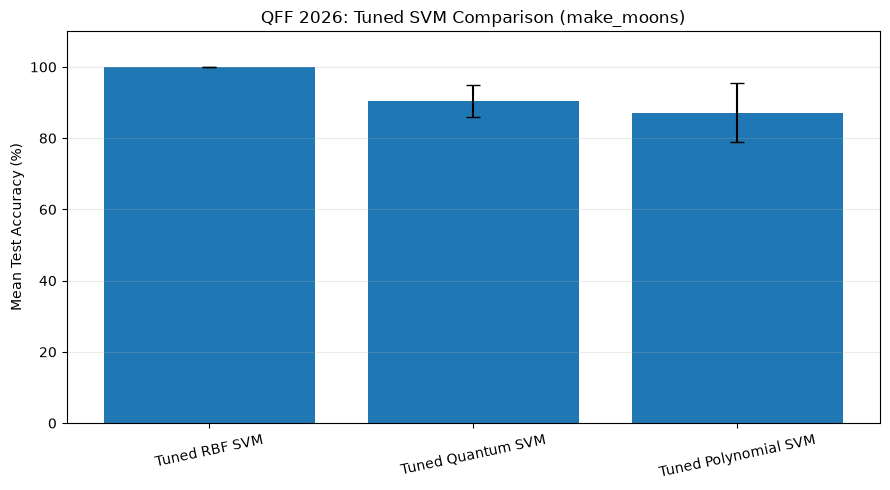

Saved: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/final_model_comparison.png


In [45]:
import matplotlib.pyplot as plt

summary = (
    final_comparison
    .groupby("model")["accuracy"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    summary.index,
    summary["mean"] * 100,
    yerr=summary["std"] * 100,
    capsize=5
)

ax.set_ylabel("Mean Test Accuracy (%)")
ax.set_title("QFF 2026: Tuned SVM Comparison (make_moons)")
ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=12)
plt.tight_layout()

output = RESULTS_DIR / "final_model_comparison.png"
plt.savefig(output, dpi=200)
plt.show()

print("Saved:", output)

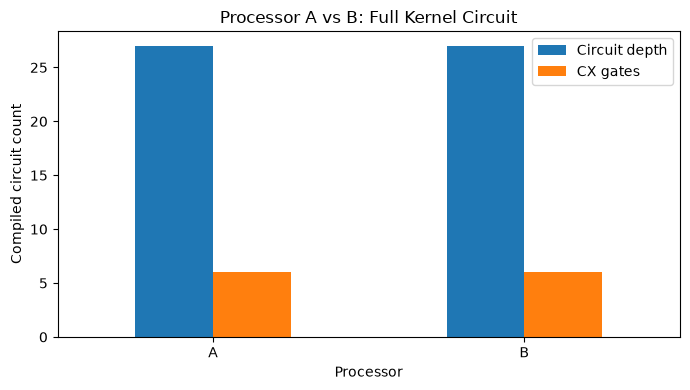

Saved: /home/chinnu/qff-2026-q-kernel-force/rebuild/results/processor_comparison.png


In [46]:
import matplotlib.pyplot as plt

ax = processor_full_results.plot(
    x="processor",
    y=["depth", "cx_gates"],
    kind="bar",
    figsize=(7, 4),
    rot=0
)

ax.set_title("Processor A vs B: Full Kernel Circuit")
ax.set_ylabel("Compiled circuit count")
ax.set_xlabel("Processor")
ax.legend(["Circuit depth", "CX gates"])

plt.tight_layout()

output = RESULTS_DIR / "processor_comparison.png"
plt.savefig(output, dpi=200)
plt.show()

print("Saved:", output)